---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Group 11

- 13524027 Aufa Rienaldifaza Ahmad
- 13524045 Ahmad Zaky Robbani
- 13524075 Hakam Avicena Mustain
- 13524087 Muhammad Fakhry Zaki
- 13524099 Muhammad Akmal

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

*To be written by the group.*

## Aim

*To be written by the group.*

## Metric

*To be written by the group.*

## Dataset

*To be written by the group.*

## Approach

*To be written by the group.*

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [6]:
# %pip install -q numpy pandas
%pip install gdown imbalanced-learn matplotlib numpy pandas scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Import Libraries

Every import of the notebook is kept in this cell.

In [ ]:
import os
import random
import sys
from pathlib import Path
import joblib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import calendar

from sklearn.base import clone
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import f1_score, ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split, StratifiedKFold, ParameterGrid
from sklearn.feature_selection import mutual_info_classif
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA


sys.path.insert(0, str(Path.cwd() / 'src'))

pd.set_option('display.max_columns', None)

## Settings

Paths and shared constants are kept in this class.

In [8]:
class Settings:
    SEED       = 42
    N_FOLDS = 5 
    DATA_DIR   = Path('data')
    OUTPUT_DIR = Path('output')
    ID_COLUMN = 'id'
    TARGET = 'is_canceled'

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [9]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [10]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [11]:
num_cols = [
    "num_adults", "num_children", "weekend_nights", "weekday_nights",
    "days_before_arrival", "arrival_year", "arrival_month", "arrival_day",
    "prior_cancellations", "prior_completed_bookings",
    "nightly_rate_idr", "special_requests"
]
cat_cols = ["meal_package", "room_category", "booking_channel"]
bin_cols = ["needs_parking", "is_returning_guest"]
target_col = "is_canceled"

print('\nTRAIN INFO')
train_df.info()
print('\nTEST INFO')
test_df.info()

train_df.head()


TRAIN INFO
<class 'pandas.DataFrame'>
RangeIndex: 27373 entries, 0 to 27372
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        27373 non-null  str    
 1   num_adults                26564 non-null  float64
 2   num_children              24338 non-null  float64
 3   weekend_nights            27373 non-null  int64  
 4   weekday_nights            27373 non-null  int64  
 5   meal_package              25613 non-null  str    
 6   needs_parking             26291 non-null  float64
 7   room_category             26371 non-null  str    
 8   days_before_arrival       26250 non-null  float64
 9   arrival_year              27373 non-null  int64  
 10  arrival_month             27373 non-null  int64  
 11  arrival_day               27373 non-null  int64  
 12  booking_channel           27373 non-null  str    
 13  is_returning_guest        27373 non-null  int64  
 14  prior

,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


## Explore Data

This part covers distributions and relationships between attributes.

is_canceled
0    18404
1     8969
Name: count, dtype: int64

Target distribution (%)
is_canceled
0    67.23
1    32.77
Name: proportion, dtype: float64


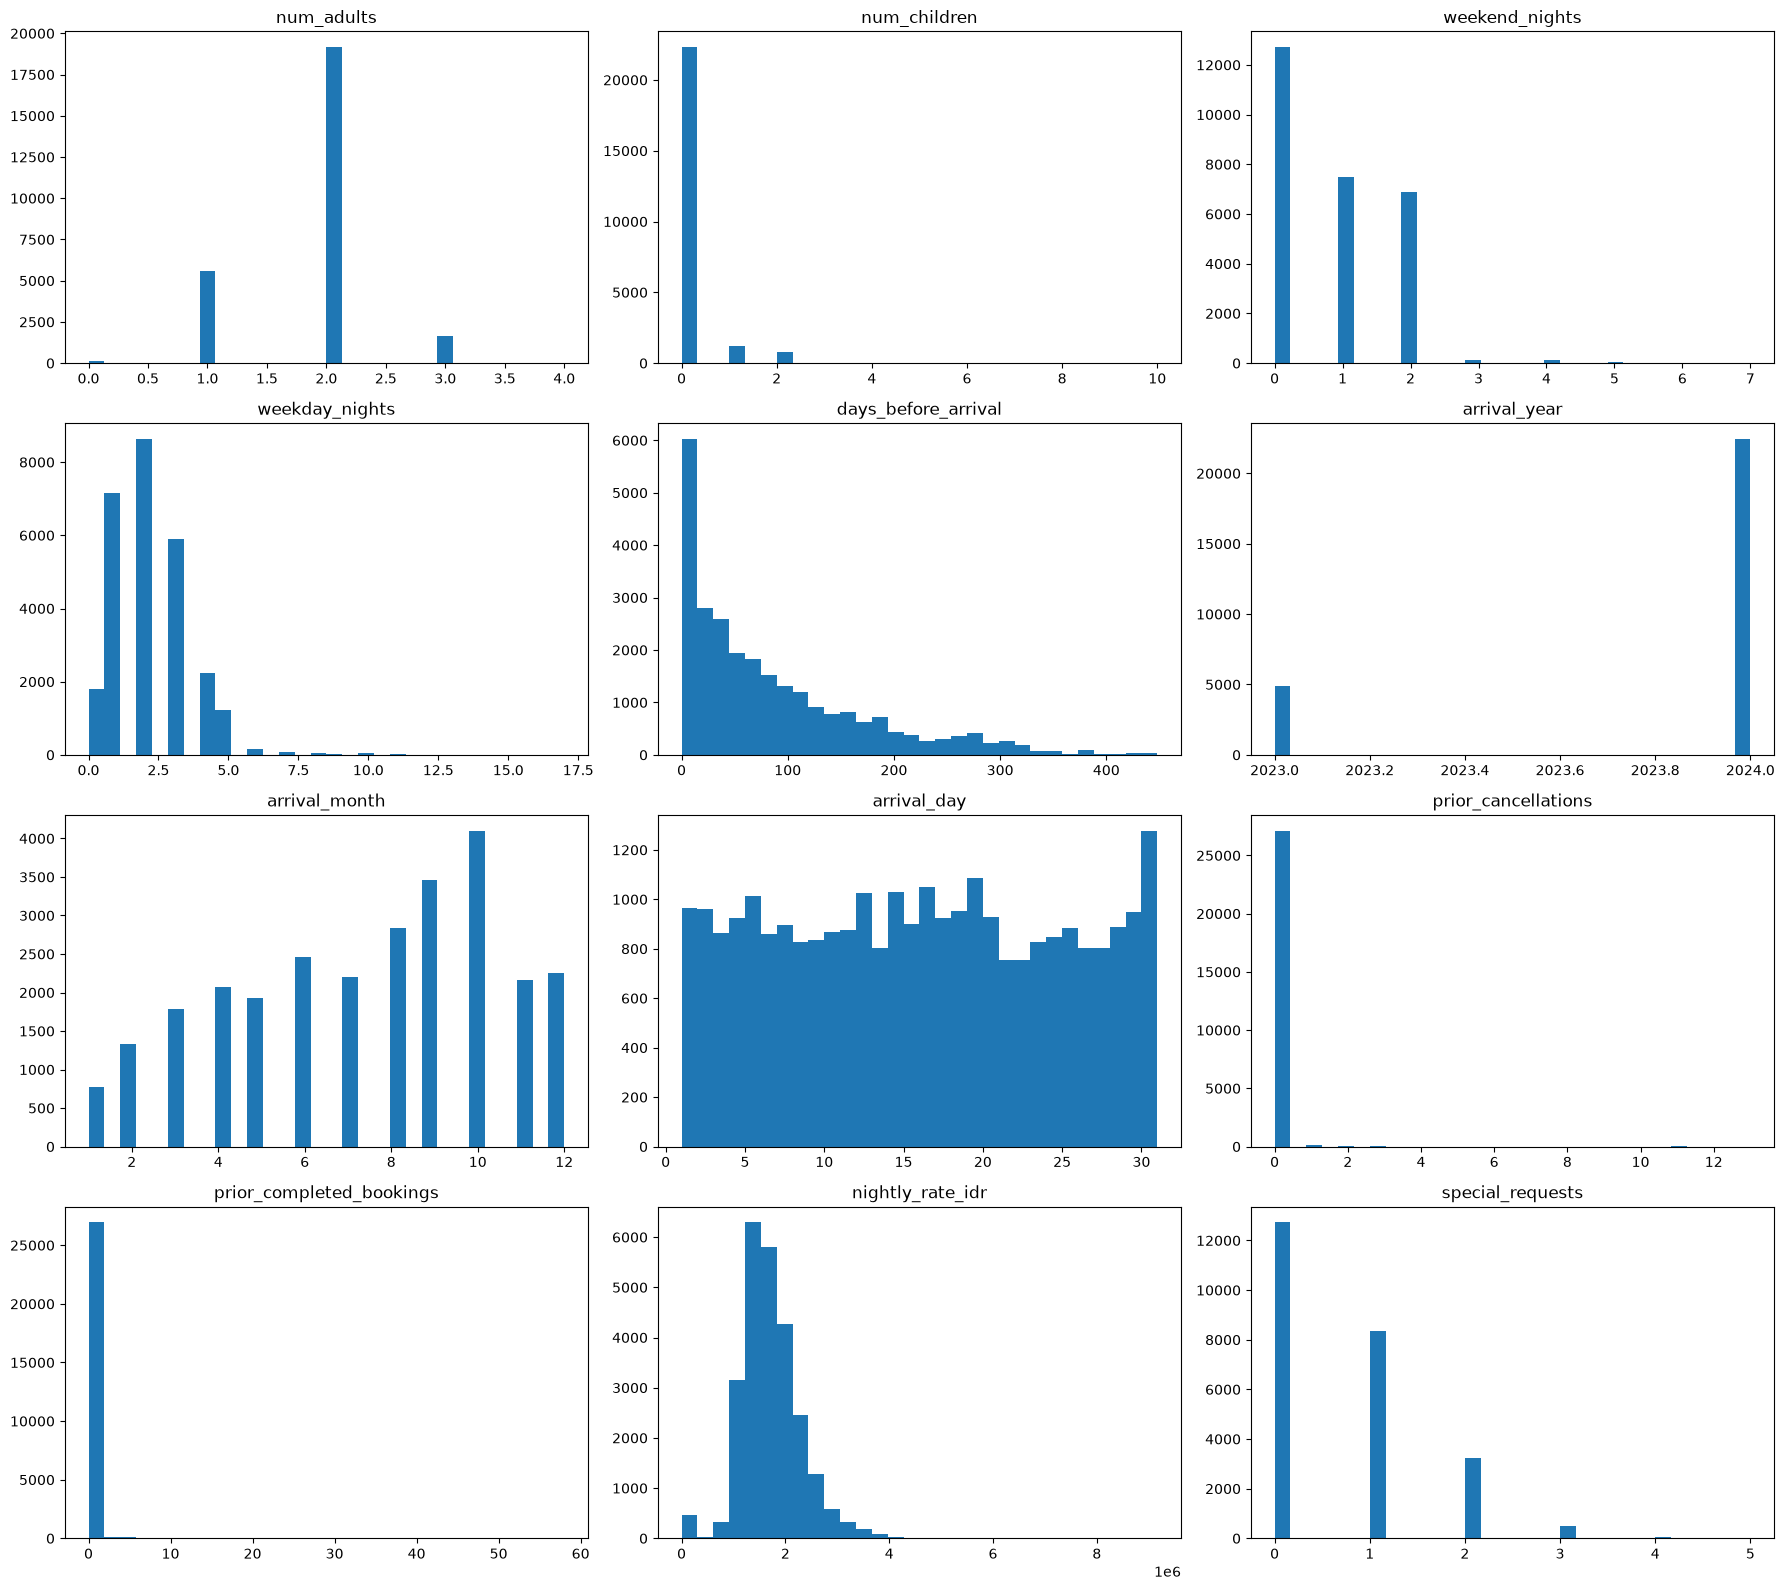

--- meal_package ---
meal_package
Breakfast     19654
Room Only      3713
Half Board     2242
NaN            1760
Full Board        4
Name: count, dtype: int64
--- room_category ---
room_category
Type B    20447
Type G     4396
NaN        1002
Type A      699
Type D      514
Type C      189
Type F      119
Type E        7
Name: count, dtype: int64
--- booking_channel ---
booking_channel
Online Travel Agent    17511
Offline Agent           7960
Corporate               1513
Complimentary            301
Airline                   88
Name: count, dtype: int64
--- needs_parking ---
needs_parking
0.0    25497
NaN     1082
1.0      794
Name: count, dtype: int64
--- is_returning_guest ---
is_returning_guest
0    26684
1      689
Name: count, dtype: int64


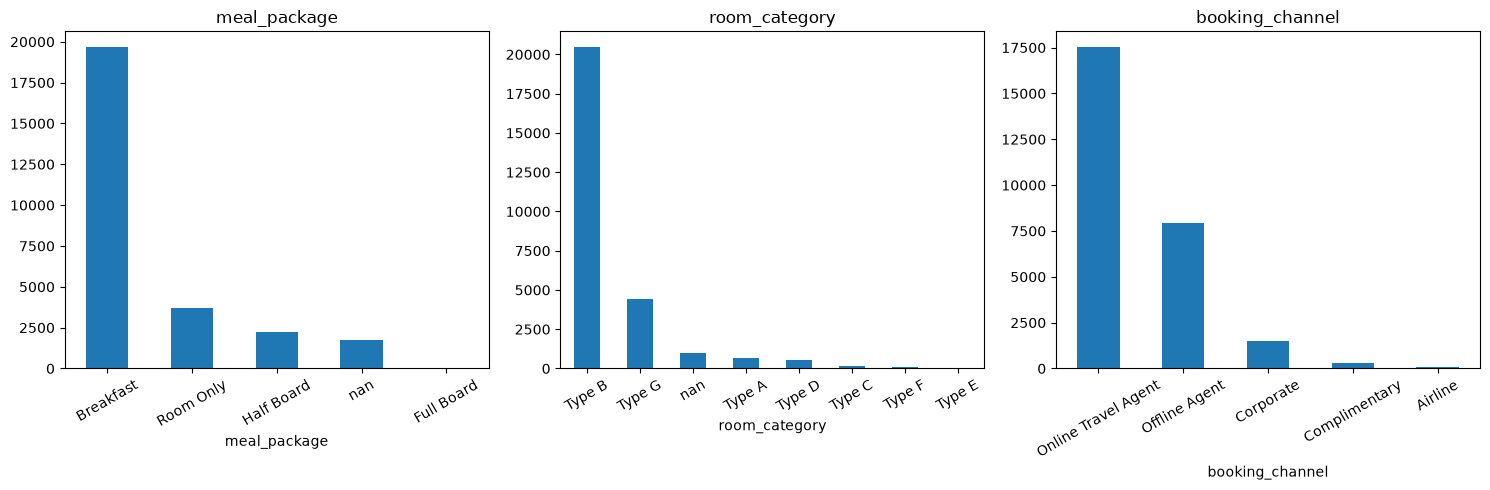


Numeric correlations with target:
days_before_arrival         0.440316
arrival_year                0.179826
nightly_rate_idr            0.134092
weekday_nights              0.097226
num_adults                  0.088446
weekend_nights              0.060797
num_children                0.030856
arrival_day                 0.020005
arrival_month              -0.015912
prior_cancellations        -0.035006
prior_completed_bookings   -0.058894
special_requests           -0.257996
Name: is_canceled, dtype: float64


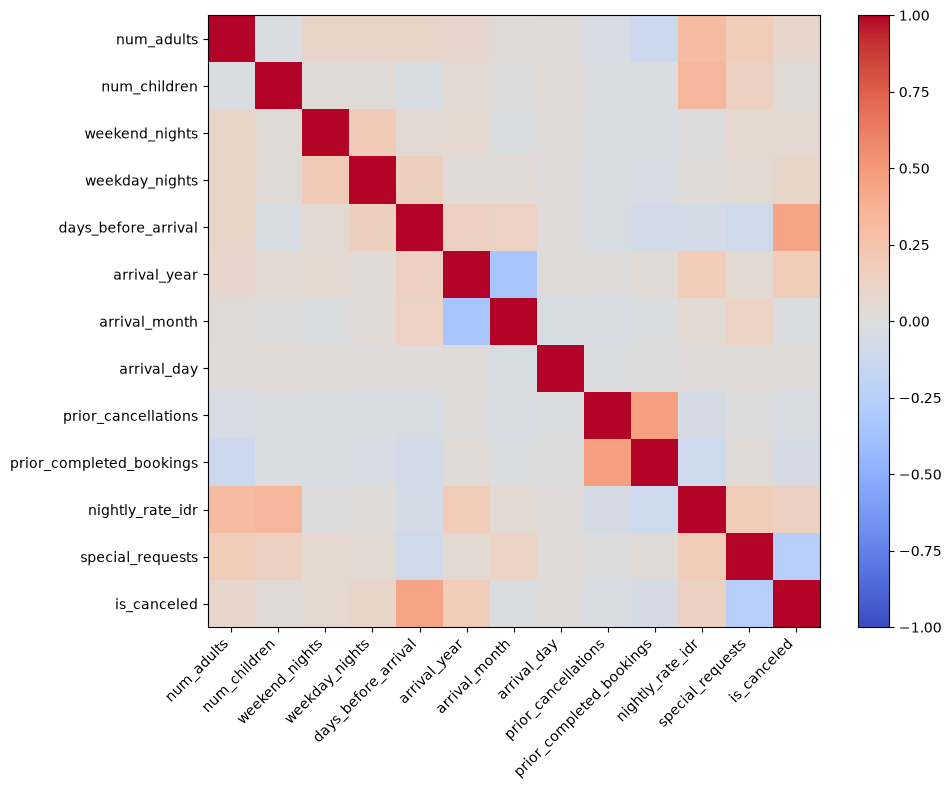


Cancellation rate by meal_package:
meal_package
Half Board    0.459
Room Only     0.338
NaN           0.319
Breakfast     0.311
Full Board    0.250
Name: is_canceled, dtype: float64

Cancellation rate by room_category:
room_category
Type A    0.426
NaN       0.348
Type G    0.342
Type D    0.329
Type B    0.321
Type E    0.286
Type C    0.249
Type F    0.244
Name: is_canceled, dtype: float64

Cancellation rate by booking_channel:
booking_channel
Online Travel Agent    0.364
Airline                0.307
Offline Agent          0.302
Corporate              0.115
Complimentary          0.000
Name: is_canceled, dtype: float64


In [12]:
print(train_df[target_col].value_counts())
print('\nTarget distribution (%)')
print((train_df[target_col].value_counts(normalize=True) * 100).round(2))

fig, axes = plt.subplots(4, 3, figsize=(18, 16))
for axis, column in zip(axes.flat, num_cols):
    axis.hist(train_df[column].dropna(), bins=30)
    axis.set_title(column)
plt.tight_layout()
plt.show()

for column in cat_cols + bin_cols:
    print(f'--- {column} ---')
    print(train_df[column].value_counts(dropna=False))

fig, axes = plt.subplots(1, len(cat_cols), figsize=(15, 5))
for axis, column in zip(axes, cat_cols):
    train_df[column].value_counts(dropna=False).plot(kind='bar', ax=axis)
    axis.set_title(column)
    axis.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

correlation = train_df[num_cols + [target_col]].corr()
print('\nNumeric correlations with target:')
print(correlation[target_col].drop(target_col).sort_values(ascending=False))
fig, axis = plt.subplots(figsize=(10, 8))
image = axis.imshow(correlation, cmap='coolwarm', vmin=-1, vmax=1)
axis.set_xticks(range(len(correlation.columns)), correlation.columns, rotation=45, ha='right')
axis.set_yticks(range(len(correlation.index)), correlation.index)
fig.colorbar(image, ax=axis)
plt.tight_layout()
plt.show()

for column in cat_cols:
    rate = train_df.groupby(column, dropna=False)[target_col].mean().sort_values(ascending=False)
    print(f'\nCancellation rate by {column}:')
    print(rate.round(3))

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [13]:
def missing_report(df, name):
    miss = df.isna().sum()
    pct = (miss / len(df) * 100).round(2)
    report = pd.DataFrame({"missing_count": miss, "missing_pct": pct})
    report = report[report["missing_count"] > 0].sort_values("missing_pct", ascending=False)
    print(f"--- Missing values: {name} ---")
    print(report if not report.empty else "Tidak ada missing value.")
    return report

In [14]:
def iqr_outlier_count(series: pd.Series) -> int:
    values = series.dropna()
    if values.empty:
        return 0

    q1, q3 = values.quantile(0.25), values.quantile(0.75)
    iqr = q3 - q1
    lower_bound, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((values < lower_bound) | (values > upper_bound)).sum())

In [15]:
def invalid_date_mask(df: pd.DataFrame) -> pd.Series:
    required_columns = {"arrival_year", "arrival_month", "arrival_day"}
    missing_columns = required_columns.difference(df.columns)
    if missing_columns:
        raise ValueError(
            f"Missing required columns: {', '.join(sorted(missing_columns))}"
        )

    def is_invalid_date(row: pd.Series) -> bool:
        try:
            max_day = calendar.monthrange(
                int(row["arrival_year"]), int(row["arrival_month"])
            )[1]
            return row["arrival_day"] > max_day
        except (OverflowError, TypeError, ValueError):
            return False

    return df.apply(is_invalid_date, axis=1)

In [16]:
missing_report(train_df, 'train')
missing_report(test_df, 'test')

print('\nDuplicate rows (train):', train_df.duplicated().sum())
print('Duplicate rows (test):', test_df.duplicated().sum())
print('Duplicate ids (train):', train_df['id'].duplicated().sum())
print('Duplicate ids (test):', test_df['id'].duplicated().sum())

for column in num_cols:
    print(f'{column}: {iqr_outlier_count(train_df[column])} potential outliers (IQR rule)')

zero_nights = train_df[
    (train_df['weekend_nights'] == 0) & (train_df['weekday_nights'] == 0)
]
zero_guests = train_df[
    (train_df['num_adults'] == 0) & (train_df['num_children'] == 0)
]
print('\nBookings with zero nights:', len(zero_nights))
print('Bookings with zero guests:', len(zero_guests))

invalid_dates = train_df.loc[invalid_date_mask(train_df)]
print('Invalid arrival dates:', len(invalid_dates))

--- Missing values: train ---
                     missing_count  missing_pct
num_children                  3035        11.09
special_requests              2500         9.13
nightly_rate_idr              2038         7.45
meal_package                  1760         6.43
days_before_arrival           1123         4.10
needs_parking                 1082         3.95
room_category                 1002         3.66
num_adults                     809         2.96
--- Missing values: test ---
                     missing_count  missing_pct
num_children                   747        10.91
special_requests               593         8.66
nightly_rate_idr               540         7.89
meal_package                   442         6.46
days_before_arrival            290         4.24
needs_parking                  247         3.61
room_category                  242         3.54
num_adults                     180         2.63

Duplicate rows (train): 0
Duplicate rows (test): 0
Duplicate ids (train): 0


---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [17]:
X_test = test_df.drop(columns=[CFG.ID_COLUMN, CFG.TARGET], errors='ignore').copy()
X = train_df.drop(columns=[CFG.ID_COLUMN, CFG.TARGET])
y = train_df[CFG.TARGET]
X_train, X_val, y_train, y_val = train_test_split(
    X, y, train_size=0.75, stratify=y, random_state=CFG.SEED
)
# Preserve raw rows: preprocessing is fitted separately within every CV fold.
X_train_raw, X_val_raw = X_train.copy(), X_val.copy()
pd.Series({'X_train': len(X_train), 'X_val': len(X_val), 'X_test': len(X_test)})

X_train    20529
X_val       6844
X_test      6844
dtype: int64

---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [18]:
# Write your code here

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [19]:
class DataCleaner(BaseEstimator, TransformerMixin):
    """Fit imputation on training rows without dropping or reordering samples."""
    def fit(self, X, y=None):
        self.fill_values_ = {}
        for column in X.columns:
            values = X[column]
            if pd.api.types.is_numeric_dtype(values):
                fill = values.median()
            else:
                modes = values.mode()
                fill = modes.iloc[0] if len(modes) else 'Unknown'
            self.fill_values_[column] = 0 if pd.isna(fill) else fill
        return self

    def transform(self, X):
        return X.copy().fillna(self.fill_values_)

In [20]:
# Cleaned copies are for inspection; modeling keeps raw data until each fold.
cleaner = DataCleaner().fit(X_train_raw)
train_clean = cleaner.transform(X_train_raw)
val_clean = cleaner.transform(X_val_raw)
test_clean = cleaner.transform(X_test)
print('Missing values after cleaning:', {
    name: int(frame.isna().sum().sum())
    for name, frame in [('train', train_clean), ('validation', val_clean), ('test', test_clean)]
})

Missing values after cleaning: {'train': 0, 'validation': 0, 'test': 0}


### Duplicates

This part covers repeated records.

In [21]:
print('Duplicate rows after cleaning (train):', X_train.duplicated().sum())
print('Duplicate rows after cleaning (validation):', X_val.duplicated().sum())
print('Duplicate rows after cleaning (test):', X_test.duplicated().sum())

Duplicate rows after cleaning (train): 40
Duplicate rows after cleaning (validation): 5
Duplicate rows after cleaning (test): 3


### Outliers

This part covers values far from the rest of the data.

In [22]:
# Inspect extremes without removing genuine booking behavior.
# In particular, do not cap special_requests or booking history counts.
print(train_clean[num_cols].describe(percentiles=[0.01, 0.5, 0.99]).T)
# Log transforms below reduce skew without learning bounds from validation data.

                            count          mean            std     min  \
num_adults                20529.0  1.851332e+00       0.511951     0.0   
num_children              20529.0  1.052170e-01       0.408093     0.0   
weekend_nights            20529.0  8.195236e-01       0.876046     0.0   
weekday_nights            20529.0  2.197818e+00       1.423752     0.0   
days_before_arrival       20529.0  8.387944e+01      84.138396     0.0   
arrival_year              20529.0  2.023819e+03       0.384917  2023.0   
arrival_month             20529.0  7.395148e+00       3.078748     1.0   
arrival_day               20529.0  1.553071e+01       8.773446     1.0   
prior_cancellations       20529.0  2.148181e-02       0.359126     0.0   
prior_completed_bookings  20529.0  1.413123e-01       1.646536     0.0   
nightly_rate_idr          20529.0  1.712227e+06  564308.485950     0.0   
special_requests          20529.0  6.080666e-01       0.784088     0.0   

                              1%     

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [23]:
invalid_date_train = X_train.loc[invalid_date_mask(X_train)]
print('Invalid arrival dates after cleaning (train):', len(invalid_date_train))
print('\nInteger-like column types after cleaning:')
print(X_train[[column for column in num_cols if column in X_train.columns]].dtypes)

invalid_date_val = X_val.loc[invalid_date_mask(X_val)]
print('Invalid arrival dates after cleaning (val):', len(invalid_date_val))
print('\nInteger-like column types after cleaning:')
print(X_val[[column for column in num_cols if column in X_val.columns]].dtypes)

invalid_date_test = X_test.loc[invalid_date_mask(X_test)]
print('Invalid arrival dates after cleaning (test):', len(invalid_date_test))
print('\nInteger-like column types after cleaning:')
print(X_test[[column for column in num_cols if column in X_test.columns]].dtypes)

print('--- Cek nilai negatif (seharusnya mustahil untuk SEMUA kolom numerik) ---')
has_negative = False
for column in num_cols:
    n_negative = (X_train[column] < 0).sum()
    n_negative_val = (X_val[column] < 0).sum()
    n_negative_test = (X_test[column] < 0).sum()
    if n_negative > 0 or n_negative_test > 0 or n_negative_val > 0:
        has_negative = True
        print(f'{column}: {n_negative} negatif di train, {n_negative_val} negatif di validation, {n_negative_test} di test — PERLU DITANGANI')
    else:
        print(f'{column}: aman')

Invalid arrival dates after cleaning (train): 0

Integer-like column types after cleaning:
num_adults                  float64
num_children                float64
weekend_nights                int64
weekday_nights                int64
days_before_arrival         float64
arrival_year                  int64
arrival_month                 int64
arrival_day                   int64
prior_cancellations           int64
prior_completed_bookings      int64
nightly_rate_idr            float64
special_requests            float64
dtype: object
Invalid arrival dates after cleaning (val): 0

Integer-like column types after cleaning:
num_adults                  float64
num_children                float64
weekend_nights                int64
weekday_nights                int64
days_before_arrival         float64
arrival_year                  int64
arrival_month                 int64
arrival_day                   int64
prior_cancellations           int64
prior_completed_bookings      int64
nightly_rate_i

## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

In [24]:
class AttributeConstructor(BaseEstimator, TransformerMixin):
    def __init__(self, include_new_features=True):
        # Toggle buat fitur-fitur baru, biar efeknya ke Macro-F1 bisa dicek langsung
        self.include_new_features = include_new_features

    def fit(self, X, y=None):
        # dipelajari cuma dari training rows fold ini, jadi ga ada leakage ke val/test
        self.room_rate_median_ = X.groupby('room_category')['nightly_rate_idr'].median()
        self.global_rate_median_ = X['nightly_rate_idr'].median()
        return self

    def transform(self, X):
        result = X.copy()
        total_nights = result['weekday_nights'] + result['weekend_nights']
        total_guests = result['num_adults'] + result['num_children']
        prior_bookings = result['prior_cancellations'] + result['prior_completed_bookings']
        result['total_guests'] = total_guests
        result['has_children'] = (result['num_children'] > 0).astype(int)
        result['log_total_nights'] = np.log1p(total_nights.clip(lower=0))
        result['weekend_ratio'] = result['weekend_nights'].div(total_nights.replace(0, np.nan)).fillna(0)

        # days_before_arrival ini korelasinya ke target lumayan gede, jadi selain
        # log-transform, worth dicoba juga efek non-linear/threshold-nya
        lead_time = result['days_before_arrival'].clip(lower=0)
        result['log_days_before_arrival'] = np.log1p(lead_time)

        result['log_nightly_rate_idr'] = np.log1p(result['nightly_rate_idr'].clip(lower=0))
        result['rate_per_guest_night'] = result['nightly_rate_idr'].div(total_guests.replace(0, np.nan)).fillna(0)

        if self.include_new_features:
            # booking zero-night (kayak voucher/promo gratis) itu cancel rate-nya
            # jauh lebih kecil dari rata-rata pas di EDA, jadi mending di-flag
            # eksplisit daripada dianggep error data doang
            result['is_zero_night_stay'] = (
                (result['weekend_nights'] == 0) & (result['weekday_nights'] == 0)
            ).astype(int)

            result['days_before_arrival_bucket'] = pd.cut(
                lead_time, bins=[-1, 2, 7, 30, 90, 180, np.inf],
                labels=[0, 1, 2, 3, 4, 5],
            ).astype(int)
            result['is_last_minute'] = (lead_time <= 2).astype(int)
            result['is_far_advance'] = (lead_time >= 180).astype(int)

            # harga mentah ga bisa dibandingin langsung antar room type (Type G
            # emang wajarnya lebih mahal dari Type A), jadi mending dibikin relatif
            # ke median harga room_category yang sama aja 
            room_median = result['room_category'].map(self.room_rate_median_).fillna(self.global_rate_median_)
            result['price_vs_room_median'] = (
                result['nightly_rate_idr'].div(room_median.replace(0, np.nan)).fillna(1.0)
            )

        result['log_total_prior_bookings'] = np.log1p(prior_bookings.clip(lower=0))
        result['cancellation_ratio'] = result['prior_cancellations'].div(prior_bookings.replace(0, np.nan)).fillna(0)
        result['has_booking_history'] = (prior_bookings > 0).astype(int)
        result['month_sin'] = np.sin(2 * np.pi * (result['arrival_month'] - 1) / 12)
        result['month_cos'] = np.cos(2 * np.pi * (result['arrival_month'] - 1) / 12)
        dates = pd.to_datetime(pd.DataFrame({
            'year': result['arrival_year'], 'month': result['arrival_month'],
            'day': result['arrival_day'],
        }, index=result.index), errors='coerce')
        result['invalid_arrival_date'] = dates.isna().astype(int)
        weekday = dates.dt.day_of_week
        result['weekday_sin'] = np.sin(2 * np.pi * weekday / 7).fillna(0)
        result['weekday_cos'] = np.cos(2 * np.pi * weekday / 7).fillna(0)
        return result.drop(columns=[
            'days_before_arrival', 'nightly_rate_idr', 'weekday_nights',
            'weekend_nights', 'num_adults', 'arrival_month', 'arrival_day',
            'prior_cancellations', 'prior_completed_bookings',
        ])

Use compact booking, guest, seasonality, and booking-history features. Replace skewed lead time, price, and stay length with log representations. Keep arrival year once; omit its duplicate year flag and the complement of returning-guest status. Calendar weekday uses actual dates rather than a fixed 30-day cycle. `rate_per_guest_night` divides the nightly booking rate by party size, with zero guests represented as zero. These are hypotheses to validate with macro-F1, not guaranteed improvements; low marginal correlation alone does not justify dropping a feature.

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [25]:
# Scale every continuous engineered feature, including price per guest.
to_scale = [
    'num_children', 'total_guests', 'log_total_nights', 'weekend_ratio',
    'log_days_before_arrival', 'log_nightly_rate_idr', 'rate_per_guest_night',
    'arrival_year', 'special_requests', 'log_total_prior_bookings',
    'cancellation_ratio',
]
scale_transformer = ColumnTransformer(
    [('scale', StandardScaler(), to_scale)], remainder='passthrough',
).set_output(transform='pandas')

Continuous features use training-fitted standardization. Binary indicators, one-hot categories, and bounded calendar cycles pass through unchanged.

### Encoding

This part covers the numeric representation of categorical attributes.

In [26]:
class FeatureEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, columns=('room_category', 'booking_channel', 'meal_package')):
        self.columns = columns

    def fit(self, X, y=None):
        self.ohe_ = OneHotEncoder(sparse_output=False, handle_unknown='ignore').fit(X[list(self.columns)])
        return self

    def transform(self, X):
        columns = list(self.columns)
        encoded = pd.DataFrame(
            self.ohe_.transform(X[columns]),
            columns=self.ohe_.get_feature_names_out(columns), index=X.index,
        )
        return pd.concat([X.drop(columns=columns), encoded], axis=1)

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [ ]:
# Write your code here
pca_reducer = PCA(n_components=0.95, random_state=CFG.SEED).set_output(transform='pandas')
PCA_MODEL_NAMES = {'KNN', 'KernelSVM', 'KNeighborsClassifier', 'SVC'}

## Class Balance

This part covers the proportion of each class in the training data.

In [28]:
class_counts = y_train.value_counts().sort_index()
print(pd.DataFrame({'count': class_counts, 'fraction': class_counts / len(y_train)}))
print('Majority/minority ratio:', class_counts.max() / class_counts.min())
# No resampling is the baseline. Optional oversampling happens only on fit rows.
def resample_training(X, y, method=None):
    if method is None:
        return X, y
    if method != 'random_over':
        raise ValueError("method must be None or 'random_over'")
    rng = np.random.default_rng(CFG.SEED)
    labels = np.asarray(y)
    classes, counts = np.unique(labels, return_counts=True)
    indices = []
    for label, count in zip(classes, counts):
        available = np.flatnonzero(labels == label)
        indices.extend(available)
        indices.extend(rng.choice(available, counts.max() - count, replace=True))
    indices = rng.permutation(indices)
    return X.iloc[indices], y.iloc[indices]

             count  fraction
is_canceled                 
0            13802  0.672317
1             6727  0.327683
Majority/minority ratio: 2.051731826965958


## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [29]:
# Write your code here

---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

In [ ]:
preparation = Pipeline([
    ('clean', DataCleaner()),
    ('construct', AttributeConstructor()),
    ('encode', FeatureEncoder()),
    ('scale', scale_transformer),
    ('reduce', 'passthrough'),   
])
# Preview only. Evaluation below fits a fresh clone on each fold's raw fit rows.
prepared = clone(preparation).fit(X_train_raw, y_train)
X_train_prepared = prepared.transform(X_train_raw)
X_val_prepared = prepared.transform(X_val_raw)
X_test_prepared = prepared.transform(X_test)
X_train, X_val = X_train_raw.copy(), X_val_raw.copy()
assert CFG.TARGET not in X_test_prepared.columns
assert np.isfinite(X_train_prepared.to_numpy(dtype=float)).all()
print('Prepared shapes:', X_train_prepared.shape, X_val_prepared.shape, X_test_prepared.shape)
print('Target correlations (training only, diagnostic):')
print(X_train_prepared.assign(is_canceled=y_train).corr()['is_canceled'].drop('is_canceled').sort_values())

pca_diagnostic = clone(pca_reducer).fit(X_train_prepared)
print(
    f'PCA would keep {pca_diagnostic.n_components_} of {X_train_prepared.shape[1]} '
    f'features, explaining {pca_diagnostic.explained_variance_ratio_.sum():.3f} of the variance.'
)

Prepared shapes: (20529, 41) (6844, 41) (6844, 41)
Target correlations (training only, diagnostic):
scale__special_requests                          -0.250358
remainder__month_cos                             -0.173416
remainder__is_last_minute                        -0.145628
remainder__booking_channel_Corporate             -0.108885
remainder__has_booking_history                   -0.106797
remainder__is_returning_guest                    -0.106797
scale__log_total_prior_bookings                  -0.092023
remainder__needs_parking                         -0.082995
remainder__booking_channel_Complimentary         -0.074313
remainder__meal_package_Breakfast                -0.056061
scale__cancellation_ratio                        -0.040269
remainder__booking_channel_Offline Agent         -0.040189
remainder__is_zero_night_stay                    -0.028284
remainder__room_category_Type F                  -0.016055
remainder__weekday_sin                           -0.015828
remainder__room

---

# Modeling and Validation <a name="7"></a>

---

In [ ]:
def fit_model(model, X_fit, y_fit, method=None, prep=None):
    prep = clone(prep if prep is not None else preparation)
    if type(model).__name__ in PCA_MODEL_NAMES:
        prep.set_params(reduce=clone(pca_reducer))
    transformed = prep.fit_transform(X_fit, y_fit)
    X_resampled, y_resampled = resample_training(transformed, y_fit, method)
    fitted_model = clone(model).fit(X_resampled, y_resampled)
    return prep, fitted_model
    # return Pipeline([('preparation', prep), ('model', fitted_model)])

def fit_predict(model, X_fit, y_fit, X_eval, method=None):
    prep, fitted_model = fit_model(model, X_fit, y_fit, method)
    X_eval_prepared = prep.transform(X_eval)
    return fitted_model.predict(X_eval_prepared)
    # return fit_model(model, X_fit, y_fit, method).predict(X_eval)

def holdout(models, X_train, y_train, X_val, y_val, method=None):
    scores = {}

    for name, model in models.items():
        predicted = fit_predict(model, X_train, y_train, X_val, method)
        scores[name] = f1_score(y_val, predicted, average='macro')

    return pd.Series(scores, name='holdout').to_frame()

In [41]:
def kfold_scores(model, X, y, method=None):
    folds = StratifiedKFold(n_splits=Settings.N_FOLDS, shuffle=True, random_state=Settings.SEED)
    scores = []

    for fit_index, eval_index in folds.split(X, y):
        predicted = fit_predict(model, X.iloc[fit_index], y.iloc[fit_index], X.iloc[eval_index], method)
        scores.append(f1_score(y.iloc[eval_index], predicted, average='macro'))

    return np.array(scores)

def kfold(models, X, y, method=None):
    rows = {}

    for name, model in models.items():
        scores = kfold_scores(model, X, y, method)
        rows[name] = {'kfold_mean': scores.mean(), 'kfold_std': scores.std()}

    return pd.DataFrame(rows).T

In [42]:
def compare(holdout_table, kfold_table):
    return holdout_table.join(kfold_table).sort_values('kfold_mean', ascending=False)

In [43]:
def tune(model, grid, X, y, method=None):
    rows = []

    for params in ParameterGrid(grid):
        scores = kfold_scores(clone(model).set_params(**params), X, y, method)
        rows.append({**params, 'kfold_mean': scores.mean(), 'kfold_std': scores.std()})

    return pd.DataFrame(rows).sort_values('kfold_mean', ascending=False, ignore_index=True)

In [32]:
from ml_lib.model.knn import KNN
from ml_lib.model.dtl import DecisionTreeCART
from ml_lib.model.regression import LogisticRegression
from ml_lib.model.svm import KernelSVM


## KNN


In [33]:
knn = KNN(k=5, p=2)
knn

,k,5
,p,2


## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [34]:
dtl = DecisionTreeCART(min_samples_split=2, max_depth=5)
dtl

,max_depth,5
,min_samples_split,2
,n_features,None
,regression,False
,ccp_alpha,0.0


## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [35]:
lr = LogisticRegression(learning_rate=0.01, n_iters=100)
lr

,learning_rate,0.01
,n_iters,100


## Support Vector Machine

<!-- rubric v3: total slack, slack_total -->

This part covers the linear, polynomial, and Gaussian kernels.

In [36]:
# Write your code here
svc = KernelSVM (kernel='rbf', n_iters=100, learning_rate=0.001)
svc

,n_iters,100
,C,1
,kernel,'rbf'
,gamma,None
,degree,3
,learning_rate,0.001
,coef,None


## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [37]:
# Write your code here

## Model Evaluation

<!-- figure palette: #6d2fa3 -->

This part compares the validation results of all models.

In [38]:
models = {'knn': knn, 
          'dtl': dtl, 
          'svc': svc, 
          'lr': lr, 
        #   'gnb': gnb
          }
models

{'knn': KNN(k=5, p=2),
 'dtl': DecisionTreeCART(min_samples_split=2, max_depth=5, n_features=None, regression=False, ccp_alpha=0.0),
 'svc': KernelSVM(C=1, kernel='rbf', gamma=None, degree=3, n_iters=100, learning_rate=0.001, coef=None),
 'lr': LogisticRegression(learning_rate=0.01, n_iters=100)}

In [39]:
# holdout_table = holdout(models, X_train, y_train, X_val, y_val)
testModels = {'knn': knn}
holdout_table = holdout (testModels, X_train, y_train, X_val, y_val)
print('Macro-F1 comparison; validation retains its original class distribution:')
balance_comparison = holdout_table.rename(columns={'holdout': 'no_resampling'}).join(
    holdout(testModels, X_train, y_train, X_val, y_val, method='random_over')
    .rename(columns={'holdout': 'random_oversampling'})
)
balance_comparison

KeyboardInterrupt: 

In [40]:
# holdout_table = holdout(models, X_train, y_train, X_val, y_val)
testModels = {'dtl': dtl}
holdout_table = holdout (testModels, X_train, y_train, X_val, y_val)
print('Macro-F1 comparison; validation retains its original class distribution:')
balance_comparison = holdout_table.rename(columns={'holdout': 'no_resampling'}).join(
    holdout(testModels, X_train, y_train, X_val, y_val, method='random_over')
    .rename(columns={'holdout': 'random_oversampling'})
)
balance_comparison

Macro-F1 comparison; validation retains its original class distribution:


,no_resampling,random_oversampling
dtl,0.784343,0.782225


In [ ]:
# holdout_table = holdout(models, X_train, y_train, X_val, y_val)
testModels = {'lr': lr}
holdout_table = holdout (testModels, X_train, y_train, X_val, y_val)
print('Macro-F1 comparison; validation retains its original class distribution:')
balance_comparison = holdout_table.rename(columns={'holdout': 'no_resampling'}).join(
    holdout(testModels, X_train, y_train, X_val, y_val, method='random_over')
    .rename(columns={'holdout': 'random_oversampling'})
)
balance_comparison

Macro-F1 comparison; validation retains its original class distribution:


,no_resampling,random_oversampling
knn,0.814463,0.790112


In [ ]:
# holdout_table = holdout(models, X_train, y_train, X_val, y_val)
testModels = {'svc': svc}
holdout_table = holdout (testModels, X_train, y_train, X_val, y_val)
print('Macro-F1 comparison; validation retains its original class distribution:')
balance_comparison = holdout_table.rename(columns={'holdout': 'no_resampling'}).join(
    holdout(testModels, X_train, y_train, X_val, y_val, method='random_over')
    .rename(columns={'holdout': 'random_oversampling'})
)
balance_comparison

     pcost       dcost       gap    pres   dres
 0: -1.3802e+04 -3.4331e+04  8e+04  1e+00  2e-16
 1: -1.1477e+04 -2.0497e+04  9e+03  1e-02  3e-16


In [ ]:
kfold_table = kfold(models, X_train, y_train)
kfold_table

In [ ]:
compare(holdout_table, kfold_table)

## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

In [ ]:
gridKNN = {
    'k': [3], 
    'p': [2], 
}


In [ ]:
gridDTL = {
    'min_samples_split': [2, 3],
    'max_depth': [5],
    'ccp_alpha': [0.01],
}

In [ ]:
gridLR = {
    'learning_rate': [0.1],
    'n_iters': [50],
}


In [ ]:
gridSVM = {
    'kernel': ['rbf'], 
    'n_iters': [1000], 
    'learning_rate': [0.001]
}

In [ ]:
knn_tuned = tune(models['knn'], gridKNN, X_train, y_train)
dtl_tuned = tune(models['dtl'], gridDTL, X_train, y_train)
lr_tuned = tune(models['lr'], gridLR, X_train, y_train)
svm_tuned = tune(models['svm'], gridSVM, X_train, y_train)

In [ ]:
tuned_models = {'knn': knn_tuned, 
                'dtl': dtl_tuned, 
                'lr': lr_tuned,
                'svm': svm_tuned, 
                # 'gnb': gnb_tuned
                }
tuned_models

In [ ]:
tuning_results = {
    'knn': knn_tuned,
    'dtl': dtl_tuned,
    'lr': lr_tuned,
    'svm': svm_tuned,
    # 'gnb': gnb_tuned,
}

metric_columns = ['kfold_mean', 'kfold_std']
tuned_models = {
    name: clone(models[name]).set_params(
        **result.drop(columns=metric_columns).to_dict(orient='records')[0]
    )
    for name, result in tuning_results.items()
}

kfold_table_tuned = kfold(tuned_models, X_train, y_train)
kfold_table_tuned

holdout_table_tuned = holdout(tuned_models, X_train, y_train, X_val, y_val)
tuned_comparison = compare(holdout_table_tuned, kfold_table_tuned)

best_model_name = tuned_comparison.index[0]
tuned_comparison

---

# Comparison with Scikit Learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [31]:
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

## KNN

Model K-Nearest Neighbors pada variabel `knn`.

<!-- Use n_neighbors 17 -->

In [32]:
knn_scikit = KNeighborsClassifier(5, metric="minkowski")
knn_scikit

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None


## DTL

Model Decision Tree pada variabel `dtl`.

In [33]:
dtl_scikit = DecisionTreeClassifier(max_depth=10, min_samples_split=2, min_samples_leaf=1)
dtl_scikit

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

### Cost-Complexity Pruning Path

This part inspects how `ccp_alpha` trades tree size for Macro-F1, to justify the pruning hyperparameter search above instead of guessing a range blindly.

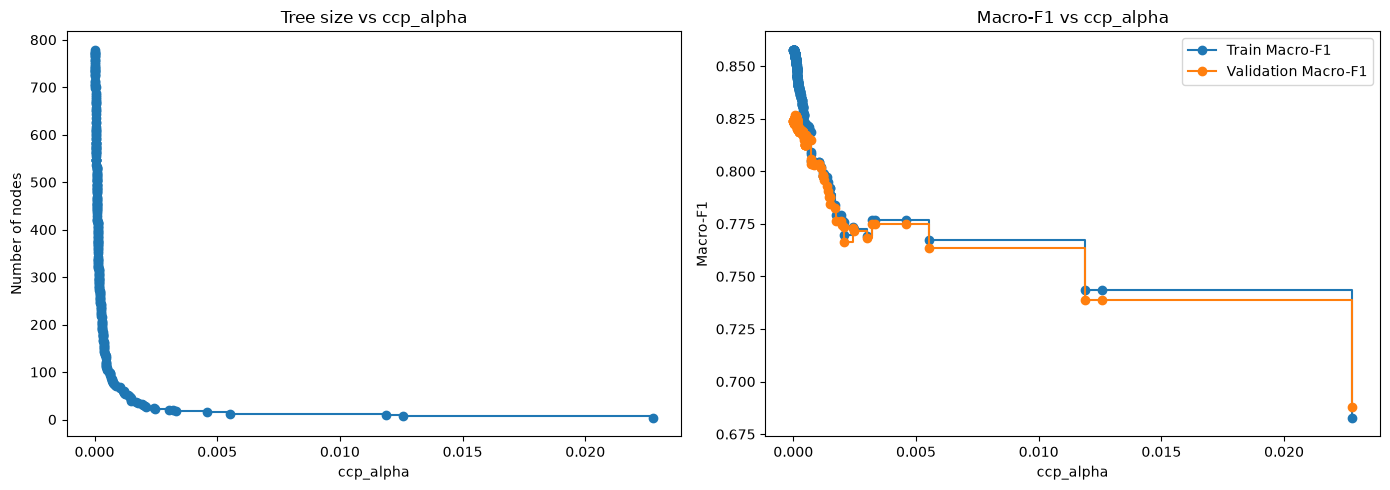

Best ccp_alpha by validation Macro-F1: 0.000079 (val F1=0.8267, nodes=537)


In [34]:
# --- Cost-Complexity Pruning Path (model optimization technique, bonus) ---
prep_for_path = clone(preparation).fit(X_train, y_train)
X_train_path = prep_for_path.transform(X_train)
X_val_path = prep_for_path.transform(X_val)

path = dtl_scikit.cost_complexity_pruning_path(X_train_path, y_train)
ccp_alphas = path.ccp_alphas[:-1]  # drop the trivial last alpha (root-only tree)

trees = [
    clone(dtl_scikit).set_params(ccp_alpha=alpha).fit(X_train_path, y_train)
    for alpha in ccp_alphas
]
node_counts = [tree.tree_.node_count for tree in trees]
train_f1 = [f1_score(y_train, tree.predict(X_train_path), average='macro') for tree in trees]
val_f1 = [f1_score(y_val, tree.predict(X_val_path), average='macro') for tree in trees]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(ccp_alphas, node_counts, marker='o', drawstyle='steps-post')
axes[0].set_xlabel('ccp_alpha')
axes[0].set_ylabel('Number of nodes')
axes[0].set_title('Tree size vs ccp_alpha')

axes[1].plot(ccp_alphas, train_f1, marker='o', label='Train Macro-F1', drawstyle='steps-post')
axes[1].plot(ccp_alphas, val_f1, marker='o', label='Validation Macro-F1', drawstyle='steps-post')
axes[1].set_xlabel('ccp_alpha')
axes[1].set_ylabel('Macro-F1')
axes[1].set_title('Macro-F1 vs ccp_alpha')
axes[1].legend()

plt.tight_layout()
plt.show()

best_idx = int(np.argmax(val_f1))
print(f'Best ccp_alpha by validation Macro-F1: {ccp_alphas[best_idx]:.6f} '
      f'(val F1={val_f1[best_idx]:.4f}, nodes={node_counts[best_idx]})')

## SVM

Model Support Vector Machine pada variabel `svc`.

In [35]:
svc_scikit = SVC(kernel="rbf")
svc_scikit

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


## Logistic Regression

Model Logistic Regression pada variabel `lr`.

In [36]:
lr_scikit = SklearnLogisticRegression(solver='liblinear', max_iter=150)
lr_scikit

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",150
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty

## Gaussian NB

Model Gaussian Naive Bayes pada variabel `gnb`.

In [37]:
gnb_scikit = GaussianNB(var_smoothing=1e-8)
gnb_scikit

,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-08
,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None


## Model Evaluation

<!-- figure palette: #6d2fa3 -->

This part compares the validation results of all models.

In [38]:
models_scikit = {'knn': knn_scikit, 
                 'dtl': dtl_scikit, 
                 'svc': svc_scikit, 
                 'lr': lr_scikit, 
                 'gnb': gnb_scikit}
models_scikit

{'knn': KNeighborsClassifier(),
 'dtl': DecisionTreeClassifier(max_depth=10),
 'svc': SVC(),
 'lr': LogisticRegression(max_iter=150, solver='liblinear'),
 'gnb': GaussianNB(var_smoothing=1e-08)}

In [44]:
for model in models_scikit : 
    print (model)
    fit_predict (models_scikit[model], X_train, y_train, X_val)

holdout_table_scikit = holdout(models_scikit, X_train, y_train, X_val, y_val, method=None)   
holdout_table_scikit

knn
dtl
svc
lr
gnb


,holdout
knn,0.814463
dtl,0.823484
svc,0.796397
lr,0.763264
gnb,0.443474


In [45]:
kfold_table_scikit = kfold(models_scikit, X_train, y_train)
kfold_table_scikit

,kfold_mean,kfold_std
knn,0.799462,0.008593
dtl,0.822089,0.004611
svc,0.792848,0.002448
lr,0.764948,0.004901
gnb,0.431008,0.014218


In [46]:
compare(holdout_table_scikit, kfold_table_scikit)

,holdout,kfold_mean,kfold_std
dtl,0.823484,0.822089,0.004611
knn,0.814463,0.799462,0.008593
svc,0.796397,0.792848,0.002448
lr,0.763264,0.764948,0.004901
gnb,0.443474,0.431008,0.014218


## Mutual Information Check

Pearson correlation only captures linear relationships, so it understates threshold/non-linear features such as `is_zero_night_stay` or `is_last_minute`. Mutual information captures non-linear dependence as well, and is checked here per feature as a complement to the ablation test below (which checks the effect on Macro-F1 per model).

In [47]:
mi_scores = mutual_info_classif(
    X_train_prepared, y_train, discrete_features='auto', random_state=CFG.SEED,
)
mi_table = pd.Series(mi_scores, index=X_train_prepared.columns, name='mutual_info').sort_values(ascending=False)
mi_table

scale__log_days_before_arrival                    0.105336
remainder__days_before_arrival_bucket             0.086859
remainder__is_far_advance                         0.054148
scale__special_requests                           0.032950
remainder__price_vs_room_median                   0.031233
scale__rate_per_guest_night                       0.025666
scale__log_nightly_rate_idr                       0.023443
remainder__month_cos                              0.018558
scale__arrival_year                               0.017855
scale__log_total_nights                           0.013642
remainder__needs_parking                          0.011792
scale__log_total_prior_bookings                   0.011493
remainder__is_last_minute                         0.011116
remainder__has_children                           0.008655
remainder__booking_channel_Corporate              0.007969
remainder__has_booking_history                    0.005271
scale__cancellation_ratio                         0.0052

## Feature Engineering Ablation

The new engineered features (`is_zero_night_stay`, `days_before_arrival_bucket`, `is_last_minute`, `is_far_advance`, `price_vs_room_median`) have near-zero Pearson correlation with the target. Pearson correlation only captures linear relationships, so a low score does not necessarily mean the feature is noise -- it is checked here directly against Macro-F1 instead.

In [48]:
preparation_with = Pipeline([
    ('clean', DataCleaner()),
    ('construct', AttributeConstructor(include_new_features=True)),
    ('encode', FeatureEncoder()),
    ('scale', scale_transformer),
])
preparation_without = Pipeline([
    ('clean', DataCleaner()),
    ('construct', AttributeConstructor(include_new_features=False)),
    ('encode', FeatureEncoder()),
    ('scale', scale_transformer),
])

def kfold_with_prep(prep, model, X, y):
    folds = StratifiedKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)
    scores = []
    for fit_idx, eval_idx in folds.split(X, y):
        pipeline = Pipeline([('preparation', clone(prep)), ('model', clone(model))])
        pipeline.fit(X.iloc[fit_idx], y.iloc[fit_idx])
        pred = pipeline.predict(X.iloc[eval_idx])
        scores.append(f1_score(y.iloc[eval_idx], pred, average='macro'))
    return np.array(scores)

ablation_rows = []
for name, model in models_scikit.items():
    with_score = kfold_with_prep(preparation_with, model, X_train, y_train).mean()
    without_score = kfold_with_prep(preparation_without, model, X_train, y_train).mean()
    ablation_rows.append({
        'model': name, 'with_new_features': with_score,
        'without_new_features': without_score, 'diff': with_score - without_score,
    })

ablation_table = pd.DataFrame(ablation_rows).set_index('model')
ablation_table

,with_new_features,without_new_features,diff
model,,,
knn,0.799462,0.793000,0.006462
dtl,0.822486,0.824207,-0.001721
svc,0.792848,0.796981,-0.004133
lr,0.764948,0.756030,0.008918
gnb,0.431008,0.375425,0.055583


## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

In [49]:
gridKNN_scikit = {
    'n_neighbors': [5], 
    'metric': ['minkowski'], 
    'weights': ['uniform', 'distance']
}


In [50]:
gridDTL_scikit = {
    'max_depth': [10],
    'min_samples_split': [2],
    'min_samples_leaf': [1],
    'ccp_alpha': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
}

In [51]:
gridSVM_scikit ={
    'kernel' : ['rbf'],
    'C' : [0.1],
    'gamma' : ['scale', 0.01, 0.1]
}


In [52]:
gridLR_scikit = {
    'max_iter': [50],
    'penalty': ['l2'],
    'C': [0.1]
}


In [53]:
gridGNB_scikit ={
    'var_smoothing': [1e-9]
}


In [54]:
knn_tuned_scikit = tune (models_scikit['knn'], gridKNN_scikit, X_train, y_train)
dtl_tuned_scikit = tune(models_scikit['dtl'], gridDTL_scikit, X_train, y_train)
svc_tuned_scikit = tune(models_scikit['svc'], gridSVM_scikit, X_train, y_train)
lr_tuned_scikit = tune(models_scikit['lr'], gridLR_scikit, X_train, y_train)
gnb_tuned_scikit = tune(models_scikit['gnb'], gridGNB_scikit, X_train, y_train)

c:\Users\Fakhry\Documents\Fakhry\Kuliah\Semester 5\Intelijensi Artifisial\Tubes2\IF3170_besokaja\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Fakhry\Documents\Fakhry\Kuliah\Semester 5\Intelijensi Artifisial\Tubes2\IF3170_besokaja\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 

In [55]:
tuned_models = {'knn': knn_tuned_scikit, 
                'dtl': dtl_tuned_scikit, 
                'svc': svc_tuned_scikit, 
                'lr': lr_tuned_scikit, 
                'gnb': gnb_tuned_scikit}
tuned_models

{'knn':       metric  n_neighbors   weights  kfold_mean  kfold_std
 0  minkowski            5  distance    0.813349   0.010933
 1  minkowski            5   uniform    0.799462   0.008593,
 'dtl':    ccp_alpha  max_depth  min_samples_leaf  min_samples_split  kfold_mean  \
 0      0.001         10                 1                  2    0.802857   
 1      0.010         10                 1                  2    0.766560   
 2      0.100         10                 1                  2    0.402027   
 3      1.000         10                 1                  2    0.402027   
 4     10.000         10                 1                  2    0.402027   
 5    100.000         10                 1                  2    0.402027   
 
    kfold_std  
 0   0.008703  
 1   0.002220  
 2   0.000039  
 3   0.000039  
 4   0.000039  
 5   0.000039  ,
 'svc':      C  gamma kernel  kfold_mean  kfold_std
 0  0.1    0.1    rbf    0.779728   0.005914
 1  0.1  scale    rbf    0.763625   0.002310
 2  0.1  

In [56]:
tuning_results_scikit = {
    'knn': knn_tuned_scikit,
    'dtl': dtl_tuned_scikit,
    'svc': svc_tuned_scikit,
    'lr': lr_tuned_scikit,
    'gnb': gnb_tuned_scikit,
}

metric_columns = ['kfold_mean', 'kfold_std']
tuned_models_scikit = {
    name: clone(models_scikit[name]).set_params(
        **result.drop(columns=metric_columns).to_dict(orient='records')[0]
    )
    for name, result in tuning_results_scikit.items()
}

kfold_table_tuned_scikit = kfold(tuned_models_scikit, X_train, y_train)
kfold_table_tuned_scikit

holdout_table_tuned_scikit = holdout(tuned_models_scikit, X_train, y_train, X_val, y_val)
tuned_comparison_scikit = compare(holdout_table_tuned_scikit, kfold_table_tuned_scikit)

best_model_name_scikit = tuned_comparison_scikit.index[0]
tuned_comparison_scikit

c:\Users\Fakhry\Documents\Fakhry\Kuliah\Semester 5\Intelijensi Artifisial\Tubes2\IF3170_besokaja\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Fakhry\Documents\Fakhry\Kuliah\Semester 5\Intelijensi Artifisial\Tubes2\IF3170_besokaja\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 

,holdout,kfold_mean,kfold_std
knn,0.821860,0.813349,0.010933
dtl,0.803262,0.802857,0.008703
svc,0.785773,0.779728,0.005914
lr,0.762009,0.764274,0.002811
gnb,0.443260,0.428777,0.016158


In [58]:
# Write your code here
# tuned_comparison
tuned_comparison_scikit

,holdout,kfold_mean,kfold_std
knn,0.821860,0.813349,0.010933
dtl,0.803262,0.802857,0.008703
svc,0.785773,0.779728,0.005914
lr,0.762009,0.764274,0.002811
gnb,0.443260,0.428777,0.016158


---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

This section stores the trained models and restores them for prediction.

In [59]:
# Write your code here

def save_model(model, name):
    path = CFG.OUTPUT_DIR / f'{name}.pkl'
    joblib.dump(model, path)
    return path

def load_model(name):
    return joblib.load(CFG.OUTPUT_DIR / f'{name}.pkl')

In [60]:
for name, model in models.items():
    fitted = fit_model(model, X_train, y_train)
    print(f'{name}: saved to {save_model(fitted, name)}')

# contoh : 
simpan_model = fit_model (tuned_models[best_model_name], X_train, y_train)
save_model(simpan_model, "best_model")

NameError: name 'models' is not defined

---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [ ]:
def submit(model, X, y, X_test, method=None):
    predictions = fit_predict(model, X, y, X_test, method)
    ids = test_df.loc[X_test.index, CFG.ID_COLUMN]
    result = pd.DataFrame({CFG.ID_COLUMN: ids, CFG.TARGET: predictions})
    assert len(result) == len(test_df)
    path = CFG.OUTPUT_DIR / 'submission.csv'
    result.to_csv(path, index=False)
    print(f'{len(result)} rows written to {path}')
    return result.head()

In [ ]:
X_final = pd.concat([X_train, X_val])
y_final = pd.concat([y_train, y_val])

# submit(tuned_models[best_model_name], X_final, y_final, X_test)
submit(testModels['knn'], X_final, y_final, X_test)

6844 rows written to output\submission.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

### Confusion Matrix

Confusion matrix serta precision dan recall kelima model.

In [ ]:
def confusion(models, X_train, y_train, X_val, y_val, method=None):
    figure, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 3.6), squeeze=False)

    for axis, (name, model) in zip(axes.flat, models.items()):
        predicted = fit_predict(model, X_train, y_train, X_val, method)
        ConfusionMatrixDisplay.from_predictions(y_val, predicted, ax=axis, colorbar=False)
        axis.set_title(name)

    plt.tight_layout()
    plt.show()

def report(models, X_train, y_train, X_val, y_val, method=None):
    tables = {}

    for name, model in models.items():
        predicted = fit_predict(model, X_train, y_train, X_val, method)
        tables[name] = pd.DataFrame(classification_report(y_val, predicted, output_dict=True)).T

    return pd.concat(tables)

In [ ]:
confusion (tuned_models, X_train, y_train, X_val, y_val)
confusion (tuned_models_scikit, X_train, y_train, X_val, y_val)

In [ ]:
report (tuned_models, X_train, y_train, X_val, y_val)
report (tuned_models_scikit, X_train, y_train, X_val, y_val)

### Misclassified Patterns

Baris asli `train` yang salah diprediksi oleh model terbaik.

In [ ]:
def misclassified(model, X_train, y_train, X_val, y_val, method=None):
    predicted = pd.Series(fit_predict(model, X_train, y_train, X_val, method), index=X_val.index)
    wrong = predicted[predicted != y_val]
    return train_df.loc[wrong.index].assign(predicted=wrong)

In [ ]:
misclassified(tuned_models[best_model_name], X_train, y_train, X_val, y_val)
misclassified(tuned_models_scikit[best_model_name_scikit], X_train, y_train, X_val, y_val)